In [1]:
import sys; sys.path.append("../src")
import json, numpy as np, pandas as pd
from data_utils import scan_dataset
from preprocessing import *

df, _ = scan_dataset("../data")
val_ok = set(df[(df.folder == "Val") & ~df.corrupted & (df.n_bad_boxes == 0)].path)

split_df = build_table("../data", val_ok_paths=val_ok)
class_names = get_class_names() 
print({c: i for i, c in enumerate(class_names)})
print(pd.crosstab(split_df.label, split_df.split))

json.dump(class_names, open("../data/class_names.json", "w"))

{'Glioma': 0, 'Meningioma': 1, 'No Tumor': 2, 'Pituitary': 3}
split       test  train  val
label                       
Glioma       184    738  124
Meningioma   182    727  134
No Tumor     102    406  100
Pituitary    178    712  136


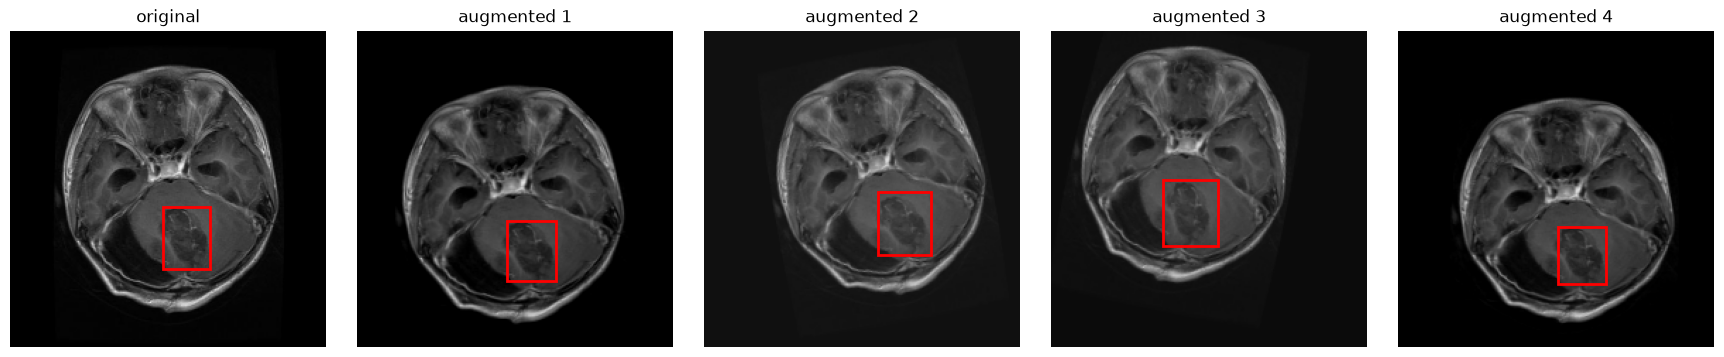

In [2]:
# 2. Augmentation on a tumor image: do the boxes follow the image?
sample = split_df[(split_df.split == "train") & (split_df.n_boxes > 0)].path.iloc[0]
show_augmentation(sample, n=4)

In [3]:
# 3. Checks: shape, value range, determinism of val/test
val_t = get_transforms(train=False)
p = split_df[split_df.split == "val"].path.iloc[0]

a, boxes_a, _ = load_sample(p, val_t)
b, boxes_b, _ = load_sample(p, val_t)
x = normalize(a)

print("shape:", x.shape, "| range:", x.min(), "to", x.max())
assert np.array_equal(a, b) and boxes_a == boxes_b
print("Val/test transform is deterministic: OK")

shape: (224, 224, 3) | range: -1.0 to 0.9843137
Val/test transform is deterministic: OK


In [4]:
# 4. Build the datasets (requires TensorFlow)
train_ds = make_dataset(split_df[split_df.split == "train"], class_names, train=True)
val_ds   = make_dataset(split_df[split_df.split == "val"],   class_names, train=False)
test_ds  = make_dataset(split_df[split_df.split == "test"],  class_names, train=False)

for x, y in train_ds.take(1):
    print(x.shape, x.dtype, y.shape, y[:8].numpy())

I0000 00:00:1792750063.609735  266354 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792750063.610288  266354 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792750063.767337  266354 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792750064.956934  266354 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

(32, 224, 224, 3) <dtype: 'float32'> (32,) [0 0 1 1 0 3 2 2]
